# Growing ring

[← All examples](../paper_examples.ipynb)

An unresolved closure search on rings of arbitrary size, with approximate dynamics. An additional example beyond the paper.


<nav class="example-sections" aria-label="Example sections" style="display:flex;align-items:stretch;gap:5px;flex-wrap:wrap;margin:16px auto;padding-top:8px;padding-bottom:8px;border-bottom:1px solid #cddce1"><span data-topic="rules" style="background:#e7f3e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=a4969ed1" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">1 · Rules &amp; state space</a></span><span data-topic="inputs" style="background:#fbe9e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=effbeb6b" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">2 · Inputs &amp; semantics</a></span><span data-topic="observables" style="background:#e8f0fb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=93cfeb9d" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">3 · Observable discovery</a></span><span data-topic="ode" style="background:#f2f3f4;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap">4 · <span aria-disabled="true" title="Unresolved" style="color:#737d83;display:inline-block;vertical-align:top">ODE<small style="display:block;font-size:10px;font-weight:400">Unresolved</small></span> &amp; <span aria-disabled="true" title="Unresolved" style="color:#737d83;display:inline-block;vertical-align:top">pJC<small style="display:block;font-size:10px;font-weight:400">Unresolved</small></span><small style="display:block"><a href="#cell-id=3bb294f9" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">Status</a></small></span><span data-topic="initial" style="background:#e3f3f0;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=fcc31e47" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">5 · Initial states</a></span><span data-topic="dynamics" style="background:#fff0de;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=6ad7adbc" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">6 · Dynamics<small style="display:block;font-size:10px;font-weight:400">Approximation</small></a></span></nav>

In [1]:
from pathlib import Path
import sys
PACKAGE = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/mfobs').is_dir()))
NOTEBOOKS = PACKAGE / 'notebooks'
sys.path[:0] = [str(NOTEBOOKS), str(PACKAGE / 'src'), str(PACKAGE)]
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
from IPython.display import display
import paper_view as view
import visual_view as visual
import visual_suite as suite
import inspection as files

<h2 id="rules" style="background:#e7f3e9;padding:12px 16px;border-radius:5px">1 · Rules & state space</h2>

Oriented rings of size ≥7, with three site states, conditional transitions, exchanges and state-copy growth.


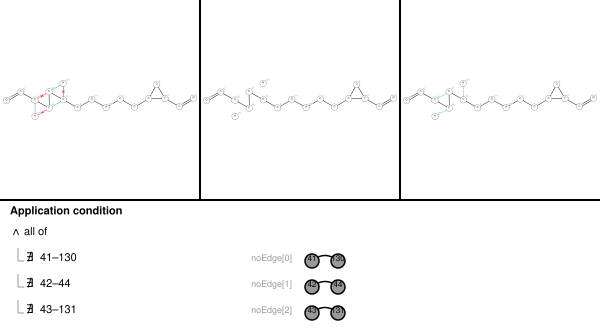

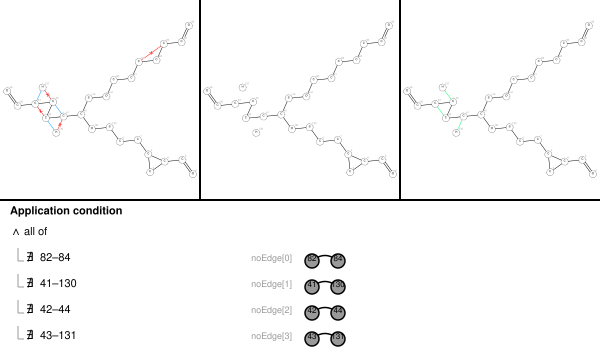

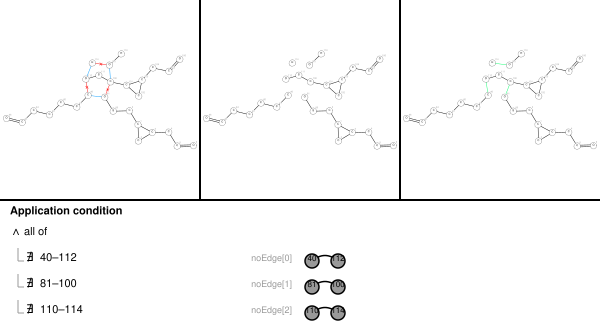

In [2]:
from mfobs import analyze as analyze_model
from mfobs.applications import GrowingRing
backend = GrowingRing()
defaults = backend.specification()
Omega = defaults.omega
rules = defaults.rules
observables = defaults.observables
from mfobs import ModelInputs
inputs = ModelInputs(Omega, rules, observables)
rule_gmls = inputs.rule_gmls()
visual.rules([(n, rule_gmls[n]) for n in ('base_10', 'guard_10_not1', 'grow_copy_0')])
files.input_rules(rule_gmls)

<h2 id="inputs" style="background:#fbe9e9;padding:12px 16px;border-radius:5px">2 · Inputs & semantics</h2>

One-site counts Q0,Q1,Q2. Their joint values do not determine all event rates.

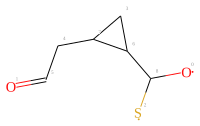

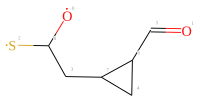

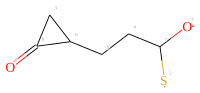

In [3]:
visual.rules(list(inputs.query_gmls().items()), identity=True)

<h2 id="observables" style="background:#e8f0fb;padding:12px 16px;border-radius:5px">3 · Observable discovery</h2>

Run 12 worklist expansions. Increase `MAX_EXPANSIONS` for a longer search.


In [4]:
MAX_EXPANSIONS = 12
result = analyze_model(inputs, worklist_limit=MAX_EXPANSIONS, include_evidence=True, backend=backend).record()
raw = result['linear_evidence']
display(view.overview(result))
suite.gml_table(raw['identity_patterns'])

,Linear closure,Event model,Coordinates,Event rows
0,UNKNOWN_EXPANSION_LIMIT,UNKNOWN_UNBOUNDED_COORDINATE_LIFT,None,None


Count,Pattern,Meaning
Q0,"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22observable-Q0%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%2032%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%2033%20label%20%22S%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%2032%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%2033%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%206%20label%20%22%3D%22%20%5D%0A%09%5D%0A%5D"" target=""_blank"" rel=""noopener"">View in MolFoundry",number of oriented consecutive occurrences of Q0
Q1,"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22observable-Q1%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%2032%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%2033%20label%20%22S%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%2032%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%2033%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%204%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%206%20label%20%22%3D%22%20%5D%0A%09%5D%0A%5D"" target=""_blank"" rel=""noopener"">View in MolFoundry",number of oriented consecutive occurrences of Q1
Q2,"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22observable-Q2%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%2032%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%2033%20label%20%22S%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%2032%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%2033%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%206%20label%20%22%3D%22%20%5D%0A%09%5D%0A%5D"" target=""_blank"" rel=""noopener"">View in MolFoundry",number of oriented consecutive 

<h2 id="ode" style="background:#f0eafb;padding:12px 16px;border-radius:5px">4 · Closure status</h2>

Both closure searches remain unresolved. The dynamics below use a one-site approximation (R1) that factorizes correlations.


In [5]:
print("Linear closure:", result["linear"]["status"])
print("Polynomial jump closure:", result["pjc"]["status"])


Linear closure: UNKNOWN_EXPANSION_LIMIT
Polynomial jump closure: UNKNOWN_UNBOUNDED_COORDINATE_LIFT


<h2 id="initial" style="background:#e3f3f0;padding:12px 16px;border-radius:5px">5 · Initial states</h2>

Initial fractions for the approximate R1 model; these do not specify a unique graph state.

In [6]:
INITIAL = [.72, .14, .14]
visual.table([dict(zip(("q0","q1","q2"),INITIAL))])

,q0,q1,q2
0,0.72,0.14,0.14


<h2 id="dynamics" style="background:#fff0de;padding:12px 16px;border-radius:5px">6 · Dynamics</h2>

Compare g=0 with positive g. These curves show approximate site fractions.


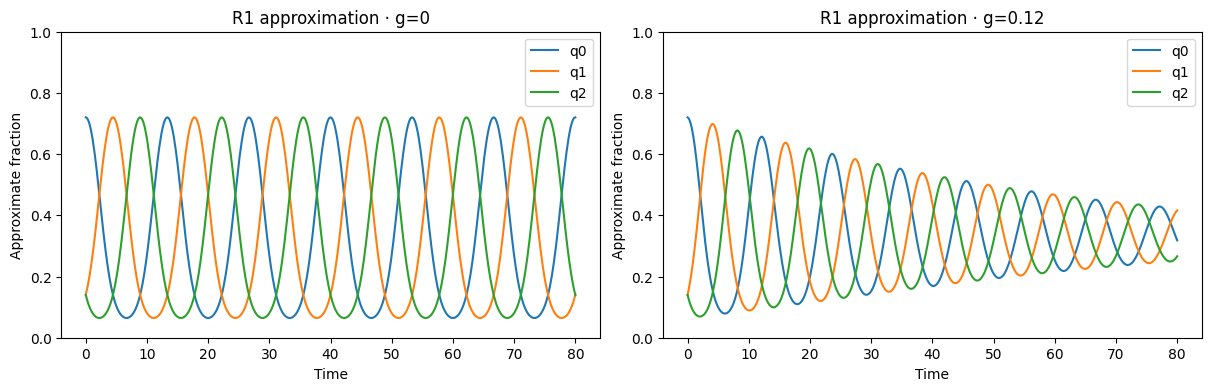

VBox(children=(FloatSlider(value=1.0, continuous_update=False, description='r', max=3.0, step=0.05), FloatSlid…

In [7]:
T = 80.0
rates = {'r': 1.0, 'g': 0.12}
curves = suite.growing_curve(INITIAL, rates, end=T)
controls = suite.rate_controls(
    lambda rates, **opts: suite.growing_curve(INITIAL, rates, **opts), rates, curves['options'])

[← All examples](../paper_examples.ipynb)